In [1]:
import sys
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.preprocessing.montagem import carregar_base
from src.preprocessing.features import separar_xy
from src.evaluation.validacao import dividir_treino_teste
from src.evaluation.negocio import (nomes_municipios, risco_por_municipio,
                                    contexto_municipio, agrupar_municipios, CONTEXTO)
from src.visualization.graficos import salvar_figura

modelo = joblib.load("../data/processed/modelo_final.joblib")
corte = pd.read_csv("../reports/metricas_teste.csv", index_col=0)["valor"]["corte"]

X, y, w, g = separar_xy(carregar_base())
_, (Xte, yte, wte, gte) = dividir_treino_teste(X, y, w, g)
proba = modelo.predict_proba(X)[:, 1]

muni = (risco_por_municipio(X, y, w, g, proba, corte)
        .merge(nomes_municipios(), on="id_municipio", how="left")
        .merge(contexto_municipio(X, g), on="id_municipio", how="left"))
muni["no_teste"] = muni["id_municipio"].isin(set(gte))

# Validacao no nivel do municipio: so municipios do teste, com pelo menos 30 alunos
val = muni.query("no_teste and alunos >= 30")
print(f"Municipios: {len(muni):,} | sem nome: {muni['municipio'].isna().sum()}")
print(f"Correlacao taxa prevista x real (teste, n={len(val)}): "
      f"{val['taxa_prevista_2024'].corr(val['taxa_real_2024']):.3f}")

Municipios: 5,517 | sem nome: 0
Correlacao taxa prevista x real (teste, n=1046): 0.787


In [2]:
cols = ["municipio", "sigla_uf", "alunos", "taxa_prevista_2024", "taxa_real_2024",
        "pct_alunos_em_risco", "taxa_2023"]
ranking = muni.query("alunos >= 30").sort_values("taxa_prevista_2024")
muni.to_csv("../reports/municipios_risco.csv", index=False)

print("20 municipios de maior risco previsto (>= 30 alunos avaliados):")
ranking[cols].head(20).round(1)

20 municipios de maior risco previsto (>= 30 alunos avaliados):


,municipio,sigla_uf,alunos,taxa_prevista_2024,taxa_real_2024,pct_alunos_em_risco,taxa_2023
2043,Macururé,BA,40,19.2,12.5,100.0,4.6
1169,Poço Branco,RN,65,20.6,25.3,100.0,10.4
1932,Entre Rios,BA,255,21.4,32.5,100.0,19.6
1900,Catolândia,BA,35,21.7,25.7,100.0,10.5
1996,Itanagra,BA,53,22.8,24.5,100.0,22.5
1898,Casa Nova,BA,430,22.8,20.9,100.0,13.1
2167,Saúde,BA,82,22.9,20.7,100.0,15.0
1837,Arataca,BA,61,23.5,13.1,100.0,16.9
2137,Santa Bárbara,BA,133,23.6,31.6,100.0,21.0
1999,Itapebi,BA,64,24.1,23.4,100.0,15.0


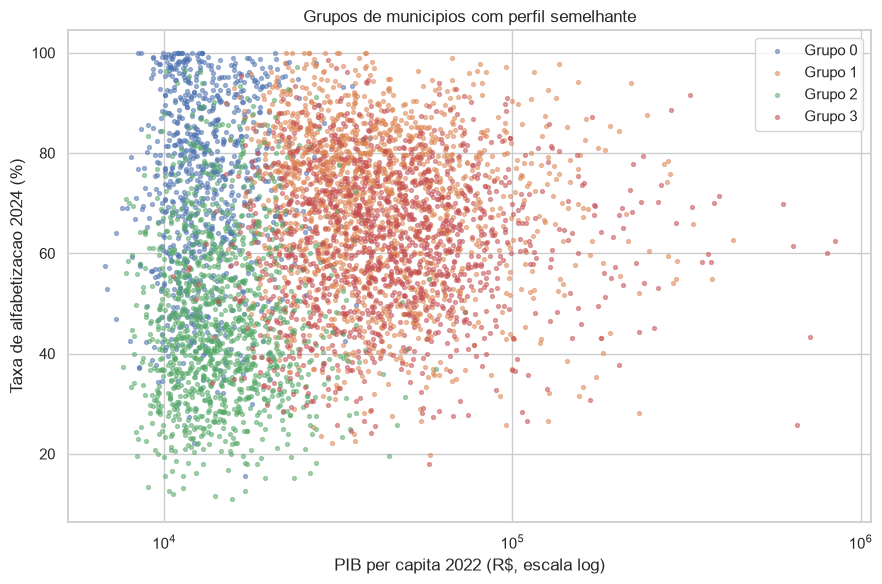

[OK] figura salva em images/negocio_01_grupos_municipios.png


,municipios,populacao_mediana,pib_pc_mediano,alfab_adultos,agro_pct,taxa_2023,taxa_real_2024,ufs_principais
grupo,,,,,,,,
0,833,11224.0,12713.8,80.3,15.8,75.7,74.0,"CE, MG, MA"
1,1651,7128.0,37940.0,92.0,40.3,68.6,69.5,"PR, MG, RS"
2,1205,13607.0,13952.4,81.4,18.5,37.9,46.6,"BA, MG, RN"
3,1284,39721.0,42887.7,94.5,7.7,59.5,62.0,"SP, MG, SC"


In [3]:
colunas_grupo = CONTEXTO + ["taxa_2023"]
base_grupo = muni.query("alunos >= 30").copy()
base_grupo["grupo"] = agrupar_municipios(base_grupo, colunas_grupo, k=4)

perfil = base_grupo.groupby("grupo").agg(
    municipios=("id_municipio", "size"),
    populacao_mediana=("populacao_2022", "median"),
    pib_pc_mediano=("pib_per_capita_2022", "median"),
    alfab_adultos=("alfabetizacao_15mais_2022", "mean"),
    agro_pct=("pib_agro_pct_2021", "mean"),
    taxa_2023=("taxa_2023", "mean"),
    taxa_real_2024=("taxa_real_2024", "mean"),
    ufs_principais=("sigla_uf", lambda s: ", ".join(s.value_counts().head(3).index)),
).round(1)
perfil.to_csv("../reports/grupos_municipios.csv")

fig, ax = plt.subplots(figsize=(9, 6))
for k, d in base_grupo.groupby("grupo"):
    ax.scatter(d["pib_per_capita_2022"], d["taxa_real_2024"], s=8, alpha=0.5, label=f"Grupo {k}")
ax.set_xscale("log")
ax.set_xlabel("PIB per capita 2022 (R$, escala log)")
ax.set_ylabel("Taxa de alfabetizacao 2024 (%)")
ax.set_title("Grupos de municipios com perfil semelhante")
ax.legend()
fig.tight_layout()
plt.show()
salvar_figura(fig, "negocio_01_grupos_municipios")
perfil  

In [2]:
from src.evaluation.negocio import taxa_municipal_prevista, projetar_ano_seguinte

metas = pd.read_parquet("../data/raw/metas_municipais.parquet")
m24 = metas.query("ano == 2024").set_index("id_municipio")

comp = taxa_municipal_prevista(modelo, X, w, g).to_frame().join(
    m24[["meta", "resultado", "meta_atingida"]], how="inner")
no_teste = comp.index.isin(set(gte))

# Calibracao da escala (microdados x indicador oficial), estimada SO nos municipios de treino
ajuste = (comp.loc[~no_teste, "resultado"] - comp.loc[~no_teste, "taxa_prevista"]).mean()
comp["taxa_ajustada"] = comp["taxa_prevista"] + ajuste
comp["previsto_atinge"] = comp["taxa_ajustada"] >= comp["meta"]

t = comp[no_teste].dropna(subset=["meta_atingida"])
nao = ~t["meta_atingida"].astype(bool)
prev_nao = ~t["previsto_atinge"]
print(f"Ajuste de escala: {ajuste:+.1f} pontos")
print(f"Municipios do teste com meta 2024: {len(t)} | nao atingiram: {nao.mean():.1%}")
print(f"Correlacao prevista x resultado oficial: {t['taxa_ajustada'].corr(t['resultado']):.3f}")
print(f"Dos que NAO atingiram, o modelo apontou: {(prev_nao & nao).sum() / nao.sum():.1%}")
print(f"Dos apontados, de fato nao atingiram:   {(prev_nao & nao).sum() / prev_nao.sum():.1%}")
pd.crosstab(t["meta_atingida"], t["previsto_atinge"], margins=True)

Ajuste de escala: +0.6 pontos
Municipios do teste com meta 2024: 1095 | nao atingiram: 48.4%
Correlacao prevista x resultado oficial: 0.749
Dos que NAO atingiram, o modelo apontou: 59.6%
Dos apontados, de fato nao atingiram:   69.6%


previsto_atinge,False,True,All
meta_atingida,,,
False,316,214,530
True,138,427,565
All,454,641,1095


In [3]:
X25 = projetar_ano_seguinte(X, g, m24["resultado"])
m25 = metas.query("ano == 2025").set_index("id_municipio")

proj = (taxa_municipal_prevista(modelo, X25, w, g).add(ajuste).to_frame()
        .join(m25[["meta"]], how="inner")
        .join(muni.set_index("id_municipio")[["municipio", "sigla_uf", "alunos"]]))
proj["gap_previsto"] = proj["taxa_prevista"] - proj["meta"]
proj["risco_nao_atingir"] = proj["gap_previsto"] < 0
proj.to_csv("../reports/projecao_metas_2025.csv")

print(f"Municipios com meta 2025: {len(proj):,} | previstos abaixo da meta: {proj['risco_nao_atingir'].mean():.1%}")
print("\n% previsto abaixo da meta, por UF (8 piores):")
print((proj.groupby("sigla_uf")["risco_nao_atingir"].mean() * 100).sort_values(ascending=False).head(8).round(1).to_string())
proj.query("alunos >= 30").sort_values("gap_previsto")[
    ["municipio", "sigla_uf", "alunos", "taxa_prevista", "meta", "gap_previsto"]].head(15).round(1)

Municipios com meta 2025: 5,232 | previstos abaixo da meta: 47.7%

% previsto abaixo da meta, por UF (8 piores):
sigla_uf
RS    99.5
BA    94.4
AM    89.6
RJ    87.8
PA    84.6
AP    68.8
RO    67.3
PR    65.6


,municipio,sigla_uf,alunos,taxa_prevista,meta,gap_previsto
id_municipio,,,,,,
4319752,São Vendelino,RS,31,23.7,80.0,-56.3
4320354,Sentinela do Sul,RS,30,21.3,75.7,-54.4
4310850,Jaboticaba,RS,35,25.9,80.0,-54.1
4313953,Pantano Grande,RS,103,21.8,74.8,-53.0
4304408,Canela,RS,465,28.1,79.1,-51.0
4314209,Pedro Osório,RS,51,21.0,71.6,-50.6
4307500,Espumoso,RS,137,29.5,80.0,-50.5
4319000,São Marcos,RS,152,29.5,80.0,-50.5
4313102,Nova Palma,RS,35,29.9,80.0,-50.1


## Conclusoes das perguntas de negocio

**Fatores que mais impactam:** UF e taxa do municipio em 2023 concentram ~75% do impacto (ver 03_interpretabilidade).

**Municipios de maior risco:** no nivel do municipio, a taxa prevista tem correlacao de 0,787 com a real nos municipios do teste. O ranking serve para priorizar. Topo dominado por BA e RN. Ressalva: o modelo confia muito no ano anterior; municipios pequenos com taxa atipica em 2023 (ex.: Ermo/SC, previsto 24,9%, real 70%) podem ser mal ordenados.

**Regioes com padroes semelhantes (KMeans, k=4):** os grupos 0 e 2 tem o mesmo perfil socioeconomico (PIB per capita ~R$ 13 mil, ~80% de adultos alfabetizados) e 27 pontos de diferenca na taxa de 2024 (74,0% x 46,6%). O grupo mais rico e urbano (3) alfabetiza menos que o grupo mais pobre (0). A taxa de 2023 entra no agrupamento, entao parte da separacao vem dela.

**Municipios que nao atingirao a meta:**
- Validacao 2024 (teste): dos apontados pelo modelo, 69,6% de fato nao atingiram (base: 48,4%, ou seja, 1,44x melhor que o acaso); o modelo encontrou 59,6% dos que nao atingiram.
- Projecao 2025 (taxa de 2024 no lugar da de 2023): 47,7% dos municipios abaixo da meta; RS, BA, AM, RJ e PA lideram.
- **Ressalva RS:** o RS teve resultado muito baixo em 2024 e a projecao o penaliza duas vezes (historico e efeito da UF). Hipotese nao testada: efeito das enchentes de maio de 2024. Se foi choque pontual, a projecao do RS e pessimista.